# 00 — Línea base
**Práctica 2 · EDA y preparación de datasets** · Rol A (Integrador)

Esta es la **referencia** contra la que todos los roles comparan sus resultados: el modelo fijo
(`LogisticRegression`) entrenado con el **preprocesamiento mínimo** de `src/utils.py`:

- imputación simple (mediana en numéricas, moda en categóricas),
- escalado estándar y one-hot,
- **sin** tratamiento de outliers y **sin** balanceo.

Reglas comunes: `RANDOM_STATE = 42`, Hold-Out estratificado 70/30, mismas métricas para todos.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from src.utils import (cargar_datos, dividir, pipeline_base, evaluar,
                       guardar_resultados, DATASETS, RANDOM_STATE, TEST_SIZE)

pd.set_option("display.precision", 4)
print(f"RANDOM_STATE = {RANDOM_STATE} · TEST_SIZE = {TEST_SIZE}")

RANDOM_STATE = 42 · TEST_SIZE = 0.3


## 1. Titanic

In [2]:
titanic = cargar_datos("titanic")
print("Dimensiones:", titanic.shape)
titanic.head()

Dimensiones: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Columnas que la línea base NO usa (identificadores / texto libre / Cabin con ~77 % de nulos)
print("Excluidas:", DATASETS["titanic"]["excluir"])

# Valores perdidos (el preprocesamiento mínimo los imputa con mediana / moda)
titanic.isna().sum().loc[lambda s: s > 0]

Excluidas: ['PassengerId', 'Name', 'Ticket', 'Cabin']


Age         177
Cabin       687
Embarked      2
dtype: int64

In [4]:
Xtr_t, Xte_t, ytr_t, yte_t = dividir(titanic, "titanic")

print("Train:", Xtr_t.shape, " Test:", Xte_t.shape)
# Comprobación de la estratificación: la proporción de la clase debe ser casi igual
pd.DataFrame({"train": ytr_t.value_counts(normalize=True),
              "test":  yte_t.value_counts(normalize=True)})

Train: (623, 7)  Test: (268, 7)


,train,test
Survived,,
0,0.6164,0.6157
1,0.3836,0.3843


In [5]:
modelo_t = pipeline_base(Xtr_t)
res_t = evaluar(modelo_t, Xtr_t, ytr_t, Xte_t, yte_t, nombre="Titanic · línea base")

--- Titanic · línea base ---
  accuracy: 0.7985
 precision: 0.7475
    recall: 0.7184
        f1: 0.7327
   roc_auc: 0.8495
    pr_auc: 0.8036
Matriz de confusión  TP=74  FP=25  FN=29  TN=140



## 2. Credit Card Fraud

In [6]:
fraud = cargar_datos("fraud")
print("Dimensiones:", fraud.shape)
print("Valores perdidos totales:", fraud.isna().sum().sum())
fraud[["Time", "Amount", "Class"]].describe()

Dimensiones: (284807, 31)
Valores perdidos totales: 0


,Time,Amount,Class
count,284807.0000,284807.0000,284807.0000
mean,94813.8596,88.3496,0.0017
std,47488.1460,250.1201,0.0415
min,0.0000,0.0000,0.0000
25%,54201.5000,5.6000,0.0000
50%,84692.0000,22.0000,0.0000
75%,139320.5000,77.1650,0.0000
max,172792.0000,25691.1600,1.0000


In [7]:
Xtr_f, Xte_f, ytr_f, yte_f = dividir(fraud, "fraud")

print("Train:", Xtr_f.shape, " Test:", Xte_f.shape)
pd.DataFrame({"train (n)": ytr_f.value_counts(), "test (n)": yte_f.value_counts(),
              "train (%)": ytr_f.value_counts(normalize=True) * 100,
              "test (%)":  yte_f.value_counts(normalize=True) * 100})

Train: (199364, 30)  Test: (85443, 30)


,train (n),test (n),train (%),test (%)
Class,,,,
0,199020,85295,99.8275,99.8268
1,344,148,0.1725,0.1732


In [8]:
modelo_f = pipeline_base(Xtr_f)
res_f = evaluar(modelo_f, Xtr_f, ytr_f, Xte_f, yte_f, nombre="Fraud · línea base")

--- Fraud · línea base ---
  accuracy: 0.9991
 precision: 0.8505
    recall: 0.6149
        f1: 0.7137
   roc_auc: 0.9567
    pr_auc: 0.7080
Matriz de confusión  TP=91  FP=16  FN=57  TN=85279



## 3. Resultados de la línea base

In [9]:
linea_base = guardar_resultados([res_t, res_f], "linea_base.csv")
linea_base

,experimento,accuracy,precision,recall,f1,roc_auc,pr_auc,TP,FP,FN,TN
0,Titanic · línea base,0.7985,0.7475,0.7184,0.7327,0.8495,0.8036,74,25,29,140
1,Fraud · línea base,0.9991,0.8505,0.6149,0.7137,0.9567,0.7080,91,16,57,85279


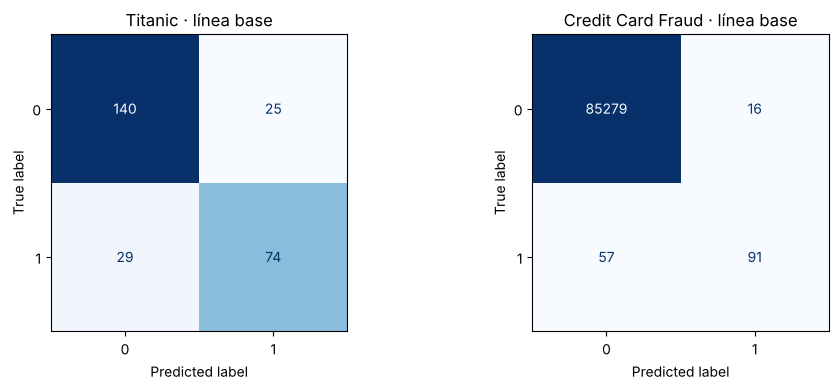

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (titulo, m, X, y) in zip(axes, [("Titanic", modelo_t, Xte_t, yte_t),
                                        ("Credit Card Fraud", modelo_f, Xte_f, yte_f)]):
    ConfusionMatrixDisplay.from_estimator(m, X, y, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{titulo} · línea base")
plt.tight_layout()
plt.savefig("../figuras/a_matrices_linea_base.png", dpi=150)
plt.show()

In [11]:
# Accuracy de un clasificador "tonto" que siempre predice la clase mayoritaria
for nombre, y in [("Titanic", yte_t), ("Fraud", yte_f)]:
    print(f"{nombre:8s} → accuracy prediciendo siempre la mayoritaria: {y.value_counts(normalize=True).max():.4f}")

Titanic  → accuracy prediciendo siempre la mayoritaria: 0.6157
Fraud    → accuracy prediciendo siempre la mayoritaria: 0.9983


## 4. Interpretación

**Titanic.** La línea base alcanza ~0.80 de accuracy y ~0.85 de ROC-AUC, claramente por encima
del 0.62 que se obtiene diciendo siempre "no sobrevive". El recall de ~0.72 indica que casi 3 de
cada 10 sobrevivientes se clasifican mal: hay margen para que la imputación (Rol D) y el balanceo
moderado (Rol E) ayuden.

**Credit Card Fraud.** El accuracy (~0.999) **no sirve**: predecir siempre "no fraude" ya da
~0.998. Las métricas que importan son **recall** (cuántos fraudes detectamos) y **PR-AUC**. Con
la distribución original el modelo solo detecta ~61 % de los fraudes (57 de 148 en test se le
escapan), aunque su precision es alta (~0.85). Este es el punto de partida contra el que el Rol E mide el efecto del balanceo.

**Uso por el equipo.** Todos comparan contra `resultados/linea_base.csv`. Si alguien cambia el
split, la semilla o el modelo, sus resultados dejan de ser comparables.